In [ ]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

Device: cuda


100.0%


Epoch 1/10, Loss: 1.7913
Epoch 2/10, Loss: 1.6661
Epoch 3/10, Loss: 1.6071
Epoch 4/10, Loss: 1.5634
Epoch 5/10, Loss: 1.5239
Epoch 6/10, Loss: 1.4898
Epoch 7/10, Loss: 1.4616
Epoch 8/10, Loss: 1.4349
Epoch 9/10, Loss: 1.4121
Epoch 10/10, Loss: 1.3913

Training Accuracy: 53.91%
Test Accuracy: 47.69%


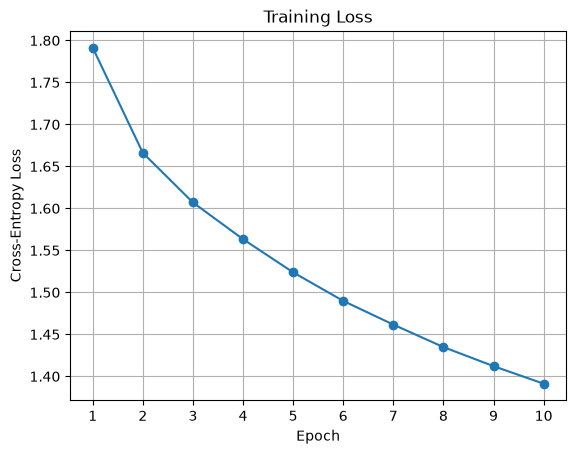

In [1]:
import math
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Load CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

# 2. Initialize network parameters
Din = 3 * 32 * 32
H = 100
K = 10

W1 = torch.randn(Din, H, device=device) * math.sqrt(2 / (Din + H))
b1 = torch.zeros(H, device=device)
W2 = torch.randn(H, K, device=device) * math.sqrt(2 / (H + K))
b2 = torch.zeros(K, device=device)

epochs = 10
lr = 0.1
lr_decay = 0.9
loss_history = []

# 3. Training with manual backpropagation
for epoch in range(epochs):
    running_loss = 0.0

    for inputs, labels in trainloader:
        X = inputs.reshape(inputs.shape[0], -1).to(device)
        labels = labels.to(device)
        N = X.shape[0]

        hidden = torch.sigmoid(X @ W1 + b1)
        logits = hidden @ W2 + b2

        loss = F.cross_entropy(logits, labels)

        probabilities = torch.softmax(logits, dim=1)
        targets = F.one_hot(labels, num_classes=K).float()
        d_logits = (probabilities - targets) / N

        dW2 = hidden.T @ d_logits
        db2 = d_logits.sum(dim=0)

        d_hidden = d_logits @ W2.T
        d_hidden_pre = d_hidden * hidden * (1 - hidden)

        dW1 = X.T @ d_hidden_pre
        db1 = d_hidden_pre.sum(dim=0)

        with torch.no_grad():
            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    loss_history.append(epoch_loss)

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.4f}")
    lr *= lr_decay

# 4. Calculate accuracy
def calculate_accuracy(loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            X = inputs.reshape(inputs.shape[0], -1).to(device)
            labels = labels.to(device)

            hidden = torch.sigmoid(X @ W1 + b1)
            logits = hidden @ W2 + b2
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

train_acc = calculate_accuracy(trainloader)
test_acc = calculate_accuracy(testloader)

print(f"\nTraining Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

# 5. Plot training loss
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

## Discussion

It can be observed that although the model's loss has been reduced with each epoch, the training and test accuracies are still low. This can be due to the model being too simple so that it underfits the dataset. Including more hidden layers can help achieve a greater accuracy.

Device: cuda


100.0%
100.0%
100.0%
100.0%


LeNet-5 | Epoch 1/10 | Train Loss: 0.1041 | Train Acc: 96.94% | Test Loss: 0.1018 | Test Acc: 96.88%
LeNet-5 | Epoch 2/10 | Train Loss: 0.0542 | Train Acc: 98.39% | Test Loss: 0.0588 | Test Acc: 98.16%
LeNet-5 | Epoch 3/10 | Train Loss: 0.0415 | Train Acc: 98.73% | Test Loss: 0.0486 | Test Acc: 98.39%
LeNet-5 | Epoch 4/10 | Train Loss: 0.0289 | Train Acc: 99.20% | Test Loss: 0.0415 | Test Acc: 98.77%
LeNet-5 | Epoch 5/10 | Train Loss: 0.0325 | Train Acc: 98.94% | Test Loss: 0.0444 | Test Acc: 98.59%
LeNet-5 | Epoch 6/10 | Train Loss: 0.0223 | Train Acc: 99.36% | Test Loss: 0.0407 | Test Acc: 98.74%
LeNet-5 | Epoch 7/10 | Train Loss: 0.0194 | Train Acc: 99.42% | Test Loss: 0.0391 | Test Acc: 98.82%
LeNet-5 | Epoch 8/10 | Train Loss: 0.0142 | Train Acc: 99.58% | Test Loss: 0.0390 | Test Acc: 98.74%
LeNet-5 | Epoch 9/10 | Train Loss: 0.0124 | Train Acc: 99.63% | Test Loss: 0.0367 | Test Acc: 98.76%
LeNet-5 | Epoch 10/10 | Train Loss: 0.0107 | Train Acc: 99.68% | Test Loss: 0.0356 | Test A

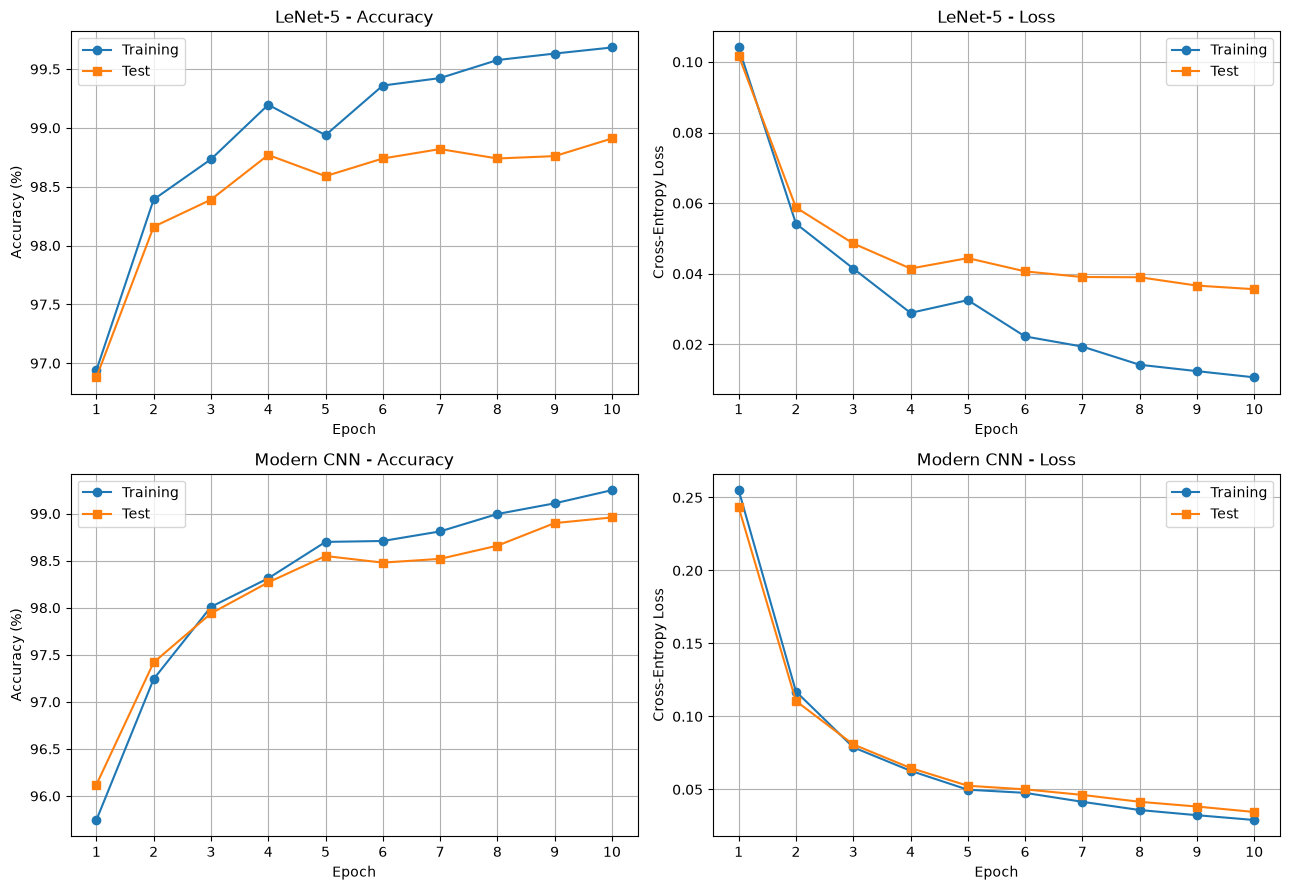

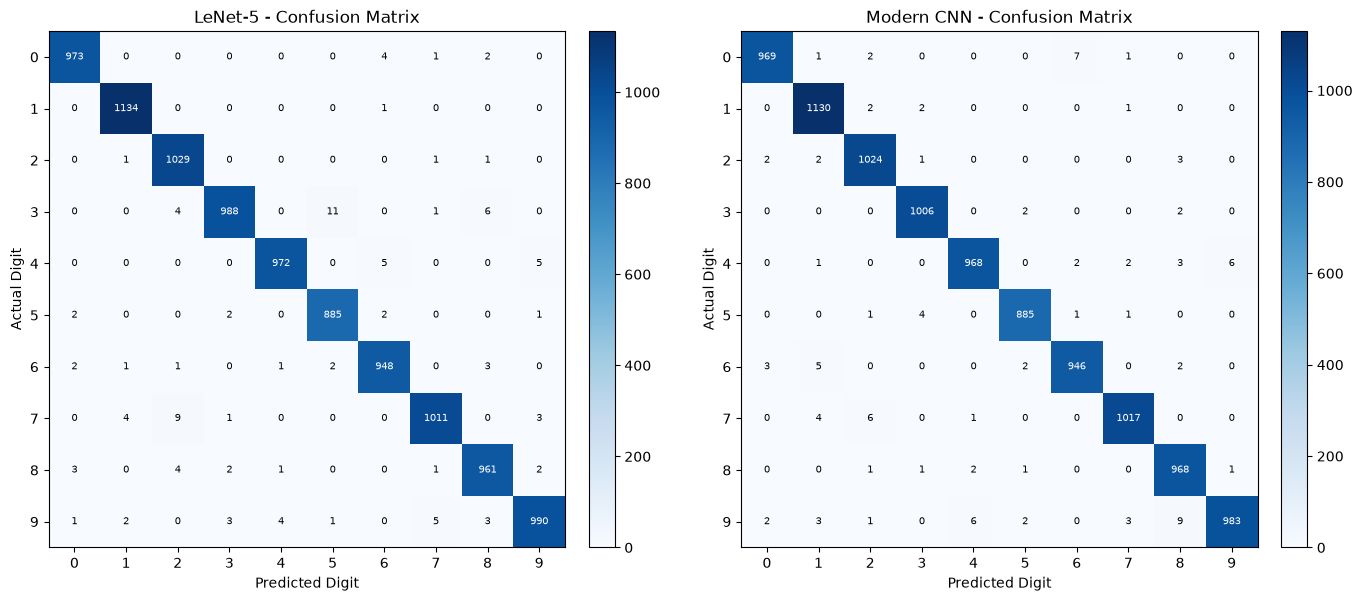

In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

batch_size = 128
epochs = 10
num_classes = 10

transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

trainset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

# LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(2, 2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Modern CNN: three convolutional layers
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


criterion = nn.CrossEntropyLoss()


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


def train_model(model, name):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [],
        "test_loss": [],
        "train_acc": [],
        "test_acc": []
    }

    for epoch in range(epochs):
        model.train()

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, trainloader)
        test_loss, test_acc = evaluate(model, testloader)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )

    return model, history


# Train both models
lenet, lenet_history = train_model(LeNet5(), "LeNet-5")
cnn, cnn_history = train_model(ModernCNN(), "Modern CNN")


# Final results after 10 epochs
print("\nFinal Results")
print("-" * 45)

for name, history in [
    ("LeNet-5", lenet_history),
    ("Modern CNN", cnn_history)
]:
    print(
        f"{name}: Training Accuracy = "
        f"{history['train_acc'][-1]:.2f}%, "
        f"Test Accuracy = {history['test_acc'][-1]:.2f}%"
    )


# Plot per-epoch accuracy and loss
histories = [
    ("LeNet-5", lenet_history),
    ("Modern CNN", cnn_history)
]

epoch_numbers = range(1, epochs + 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row, (name, history) in enumerate(histories):
    axes[row, 0].plot(
        epoch_numbers, history["train_acc"], marker="o", label="Training"
    )
    axes[row, 0].plot(
        epoch_numbers, history["test_acc"], marker="s", label="Test"
    )
    axes[row, 0].set_title(f"{name} - Accuracy")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Accuracy (%)")
    axes[row, 0].set_xticks(list(epoch_numbers))
    axes[row, 0].grid(True)
    axes[row, 0].legend()

    axes[row, 1].plot(
        epoch_numbers, history["train_loss"], marker="o", label="Training"
    )
    axes[row, 1].plot(
        epoch_numbers, history["test_loss"], marker="s", label="Test"
    )
    axes[row, 1].set_title(f"{name} - Loss")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Cross-Entropy Loss")
    axes[row, 1].set_xticks(list(epoch_numbers))
    axes[row, 1].grid(True)
    axes[row, 1].legend()

plt.tight_layout()
plt.show()


# Generate confusion matrices
@torch.no_grad()
def get_confusion_matrix(model, loader):
    model.eval()
    all_targets = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        predictions = model(images).argmax(dim=1)

        all_targets.append(labels)
        all_predictions.append(predictions.cpu())

    targets = torch.cat(all_targets)
    predictions = torch.cat(all_predictions)

    matrix = torch.bincount(
        targets * num_classes + predictions,
        minlength=num_classes ** 2
    ).reshape(num_classes, num_classes)

    return matrix.numpy()


lenet_cm = get_confusion_matrix(lenet, testloader)
cnn_cm = get_confusion_matrix(cnn, testloader)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name, matrix in [
    (axes[0], "LeNet-5", lenet_cm),
    (axes[1], "Modern CNN", cnn_cm)
]:
    im = ax.imshow(matrix, cmap="Blues")
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Digit")
    ax.set_ylabel("Actual Digit")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for i in range(10):
        for j in range(10):
            ax.text(
                j, i, str(matrix[i, j]),
                ha="center", va="center", fontsize=7,
                color="white" if matrix[i, j] > matrix.max() / 2 else "black"
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


Device: cuda
Dataset downloaded and extracted.
Classes: ['ants', 'bees']
Training images: 244
Validation images: 153
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\arosh/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Fine-tuning | Epoch 01/25 | Train Loss: 0.6514 | Train Acc: 64.75% | Val Loss: 0.3091 | Val Acc: 84.97%
Fine-tuning | Epoch 02/25 | Train Loss: 0.4948 | Train Acc: 80.33% | Val Loss: 0.2715 | Val Acc: 87.58%
Fine-tuning | Epoch 03/25 | Train Loss: 0.7566 | Train Acc: 73.77% | Val Loss: 0.3992 | Val Acc: 85.62%
Fine-tuning | Epoch 04/25 | Train Loss: 0.4581 | Train Acc: 81.97% | Val Loss: 0.2961 | Val Acc: 86.93%
Fine-tuning | Epoch 05/25 | Train Loss: 0.5590 | Train Acc: 79.92% | Val Loss: 0.3595 | Val Acc: 86.93%
Fine-tuning | Epoch 06/25 | Train Loss: 0.5783 | Train Acc: 77.05% | Val Loss: 0.4629 | Val Acc: 84.97%
Fine-tuning | Epoch 07/25 | Train Loss: 1.0247 | Train Acc: 70.08% | Val Loss: 0.3041 | Val Acc: 90.20%
Fine-tuning | Epoch 08/25 | Train Loss: 0.3716 | Train Acc: 84.84% | Val Loss: 0.2649 | Val Acc: 90.85%
Fine-tuning | Epoch 09/25 | Train Loss: 0.4896 | Train Acc: 79.10% | Val Loss: 0.2383 | Val Acc: 93.46%
Fine-tuning | Epoch 10/25 | Train Loss: 0.4044 | Train Acc: 82.7

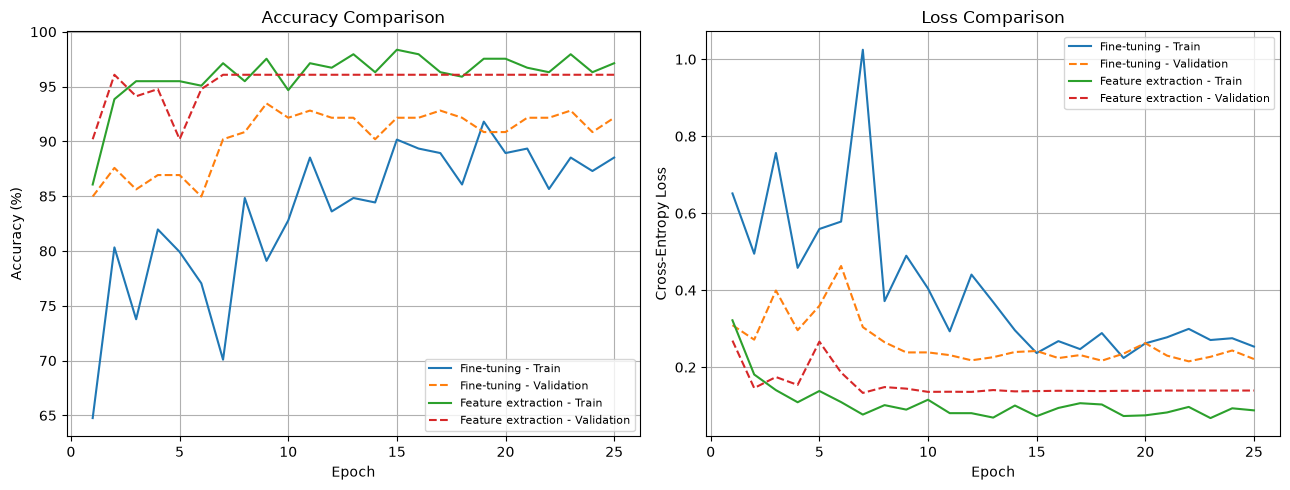

Both trained models have been saved.


In [2]:
import copy
import time
import zipfile
import urllib.request
from pathlib import Path

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Download and load Hymenoptera dataset
data_root = Path("./data")
dataset_dir = data_root / "hymenoptera_data"
zip_path = data_root / "hymenoptera_data.zip"
data_root.mkdir(parents=True, exist_ok=True)

if not (dataset_dir / "train").is_dir() or not (dataset_dir / "val").is_dir():
    if not zip_path.exists():
        print("Downloading Hymenoptera dataset...")
        urllib.request.urlretrieve(
            "https://download.pytorch.org/tutorial/hymenoptera_data.zip",
            zip_path
        )

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(data_root)

    print("Dataset downloaded and extracted.")

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

image_datasets = {
    phase: torchvision.datasets.ImageFolder(
        dataset_dir / phase,
        transform=data_transforms[phase]
    )
    for phase in ["train", "val"]
}

dataloaders = {
    "train": torch.utils.data.DataLoader(
        image_datasets["train"],
        batch_size=4,
        shuffle=True,
        num_workers=0
    ),
    "val": torch.utils.data.DataLoader(
        image_datasets["val"],
        batch_size=4,
        shuffle=False,
        num_workers=0
    )
}

dataset_sizes = {
    phase: len(image_datasets[phase])
    for phase in ["train", "val"]
}
class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", dataset_sizes["train"])
print("Validation images:", dataset_sizes["val"])

# 2. Training and validation function
criterion = nn.CrossEntropyLoss()
num_epochs = 25

def train_model(model, name, optimizer, scheduler, feature_extractor=False):
    model = model.to(device)
    history = []
    best_acc = 0.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    start_time = time.time()

    for epoch in range(num_epochs):
        metrics = {}

        for phase in ["train", "val"]:
            if phase == "train":
                if feature_extractor:
                    model.eval()
                    model.fc.train()
                else:
                    model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            with torch.set_grad_enabled(phase == "train"):
                for images, labels in dataloaders[phase]:
                    images = images.to(device)
                    labels = labels.to(device)

                    if phase == "train":
                        optimizer.zero_grad(set_to_none=True)

                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    predictions = outputs.argmax(dim=1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                    running_loss += loss.item() * images.size(0)
                    running_corrects += (
                        predictions == labels
                    ).sum().item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]

            metrics[f"{phase}_loss"] = epoch_loss
            metrics[f"{phase}_acc"] = epoch_acc * 100

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_epoch = epoch + 1
                best_weights = copy.deepcopy(model.state_dict())

        history.append(metrics)
        scheduler.step()

        print(
            f"{name} | Epoch {epoch + 1:02d}/{num_epochs} | "
            f"Train Loss: {metrics['train_loss']:.4f} | "
            f"Train Acc: {metrics['train_acc']:.2f}% | "
            f"Val Loss: {metrics['val_loss']:.4f} | "
            f"Val Acc: {metrics['val_acc']:.2f}%"
        )

    model.load_state_dict(best_weights)
    elapsed = time.time() - start_time

    print(
        f"\n{name}: Best validation accuracy = "
        f"{best_acc * 100:.2f}% at epoch {best_epoch}"
    )
    print(f"Training time: {elapsed / 60:.2f} minutes\n")

    return model, history, best_epoch, elapsed


# 3. Fine-tuning: train the complete ResNet18
weights = torchvision.models.ResNet18_Weights.DEFAULT

model_ft = torchvision.models.resnet18(weights=weights)
num_features = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_features, len(class_names))
model_ft = model_ft.to(device)

optimizer_ft = torch.optim.SGD(
    model_ft.parameters(), lr=0.001, momentum=0.9
)
scheduler_ft = torch.optim.lr_scheduler.StepLR(
    optimizer_ft, step_size=7, gamma=0.1
)

model_ft, history_ft, best_epoch_ft, time_ft = train_model(
    model_ft,
    "Fine-tuning",
    optimizer_ft,
    scheduler_ft
)


# 4. Feature extraction: freeze ResNet18 and train only its final layer
model_fe = torchvision.models.resnet18(weights=weights)

for param in model_fe.parameters():
    param.requires_grad = False

num_features = model_fe.fc.in_features
model_fe.fc = nn.Linear(num_features, len(class_names))
model_fe = model_fe.to(device)

optimizer_fe = torch.optim.SGD(
    model_fe.fc.parameters(), lr=0.001, momentum=0.9
)
scheduler_fe = torch.optim.lr_scheduler.StepLR(
    optimizer_fe, step_size=7, gamma=0.1
)

model_fe, history_fe, best_epoch_fe, time_fe = train_model(
    model_fe,
    "Feature extraction",
    optimizer_fe,
    scheduler_fe,
    feature_extractor=True
)


# 5. Compare the best validation results
print("=" * 76)
print("FINAL COMPARISON")
print("=" * 76)
print(
    f"{'Method':<22}{'Best Epoch':>12}"
    f"{'Train Acc':>13}{'Val Acc':>12}{'Time (min)':>14}"
)

for name, history, best_epoch, elapsed in [
    ("Fine-tuning", history_ft, best_epoch_ft, time_ft),
    ("Feature extraction", history_fe, best_epoch_fe, time_fe)
]:
    best_metrics = history[best_epoch - 1]

    print(
        f"{name:<22}{best_epoch:>12}"
        f"{best_metrics['train_acc']:>12.2f}%"
        f"{best_metrics['val_acc']:>11.2f}%"
        f"{elapsed / 60:>13.2f}"
    )


# 6. Plot training and validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
epoch_numbers = range(1, num_epochs + 1)

for name, history in [
    ("Fine-tuning", history_ft),
    ("Feature extraction", history_fe)
]:
    axes[0].plot(
        epoch_numbers,
        [h["train_acc"] for h in history],
        label=f"{name} - Train"
    )
    axes[0].plot(
        epoch_numbers,
        [h["val_acc"] for h in history],
        linestyle="--",
        label=f"{name} - Validation"
    )

    axes[1].plot(
        epoch_numbers,
        [h["train_loss"] for h in history],
        label=f"{name} - Train"
    )
    axes[1].plot(
        epoch_numbers,
        [h["val_loss"] for h in history],
        linestyle="--",
        label=f"{name} - Validation"
    )

axes[0].set_title("Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend(fontsize=8)
axes[0].grid(True)

axes[1].set_title("Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend(fontsize=8)
axes[1].grid(True)

plt.tight_layout()
plt.show()


# 7. Save the best-performing checkpoints
torch.save(model_ft.state_dict(), "resnet18_finetuned.pth")
torch.save(model_fe.state_dict(), "resnet18_feature_extractor.pth")

print("Both trained models have been saved.")
